# **CVC-ClinicDB Dataset**

In [2]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [3]:
# Dataset Paths
dataset_path = "data/CVC-ClinicDB"
image_dir = "Original"
mask_dir = "Ground Truth"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

# dataset.visualize_samples()

Total number of samples: 612
Number of training samples: 550
Number of testing samples: 62


# Unet CVC model training config

In [4]:
cfg = TrainConfig(
    # --- General ---
    model_name = "DeepLabV3Plus",
    dataset_name = "CVC-ClinicDB",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [5]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc
wandb: Currently logged in as: mironshoh (iv-drip-counter) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
model = deeplabv3plus_resnet34(num_classes=1, pretrained=False, output_stride=16)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


/media/data/Mironshoh/segmentation-paper/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/media/data/Mironshoh/segmentation-paper/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
2025-09-08 08:02:25 | INFO | DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225 | Logging to model_comparisons/logs/DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225.log
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


2025-09-08 08:02:25 | INFO | DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/vk96od92
100%|██████████| 8/8 [00:00<00:00, 14.76it/s]
2025-09-08 08:02:31 | INFO | DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225 | Epoch 001/100 | Train: 1.497820 | Val: 1.024422 | LR: 0.001000 | 5.24s | Val Dice: 0.2718 IoU: 0.1821 F1: 0.3223
2025-09-08 08:02:31 | INFO | DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225 | Saved best: model_comparisons/models/best_DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225.pth (val=1.024422)
100%|██████████| 8/8 [00:01<00:00,  6.35it/s]
2025-09-08 08:02:37 | INFO | DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225 | Epoch 002/100 | Train: 0.919556 | Val: 1.230002 | LR: 0.001000 | 5.06s | Val Dice: 0.3219 IoU: 0.2132 F1: 0.3447
2025-09-08 08:02:37 | INFO | DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225 | No improvement. ES 1/10
100%|██████████| 8/8 [00:00<00:00, 11.10it/s]
2025-09-08 08:02:42 | INFO

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,▇█▆▇▇▇█▆▇▆▇▆▇▆▇▆▂█▇█▇▆▂▁▂▇▇▄▇▇█▆▆▅▅▆▄▆▂▇
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▂▁▃▂▂▂▁▃▂▃▂▃▂▃▂▃▇▁▂▁▂▃▇█▇▂▂▅▂▂▁▃▃▄▄▃▅▃▇▂
epoch_seconds,▆▅▃█▁▄▃▃▂▂▂▃▃▂▃▃▂▂▄▃▃▃▃▃▄▃▄▄▄▄▂▂▃▂▃▃▃▄▄▄
lr,████████████████████████████████████▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▃▃▃▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇▇▇█▇██████████▇█████
train/f1,▁▂▃▃▃▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇▇▇█▇██████████▇█████
train/iou,▁▂▂▂▃▃▃▃▄▄▄▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇█████▇▇▇████
+11,...


{'best_val_loss': 0.19908397551625967,
 'epochs_ran': 45,
 'best_model_path': 'model_comparisons/models/best_DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_DeepLabV3Plus_CVC_ClinicDB_20250908_080225.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/vk96od92',
 'log_path': 'model_comparisons/logs/DeepLabV3Plus_model_CVC_ClinicDB_20250908_080225.log'}

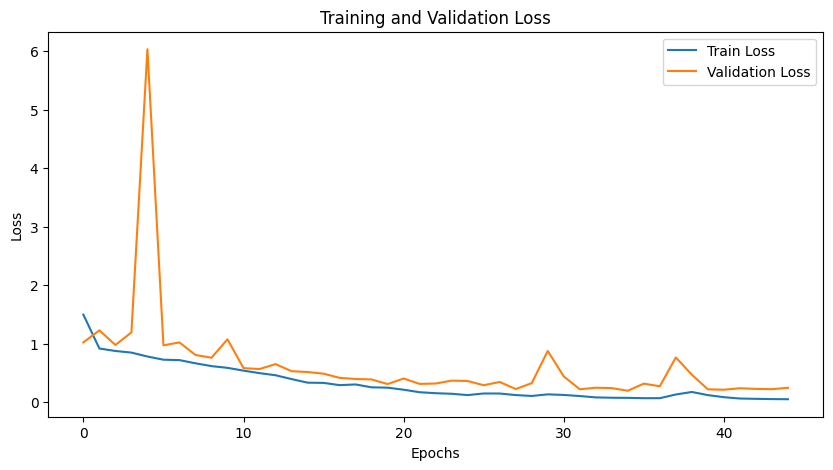

In [7]:
trainer.plot_losses()

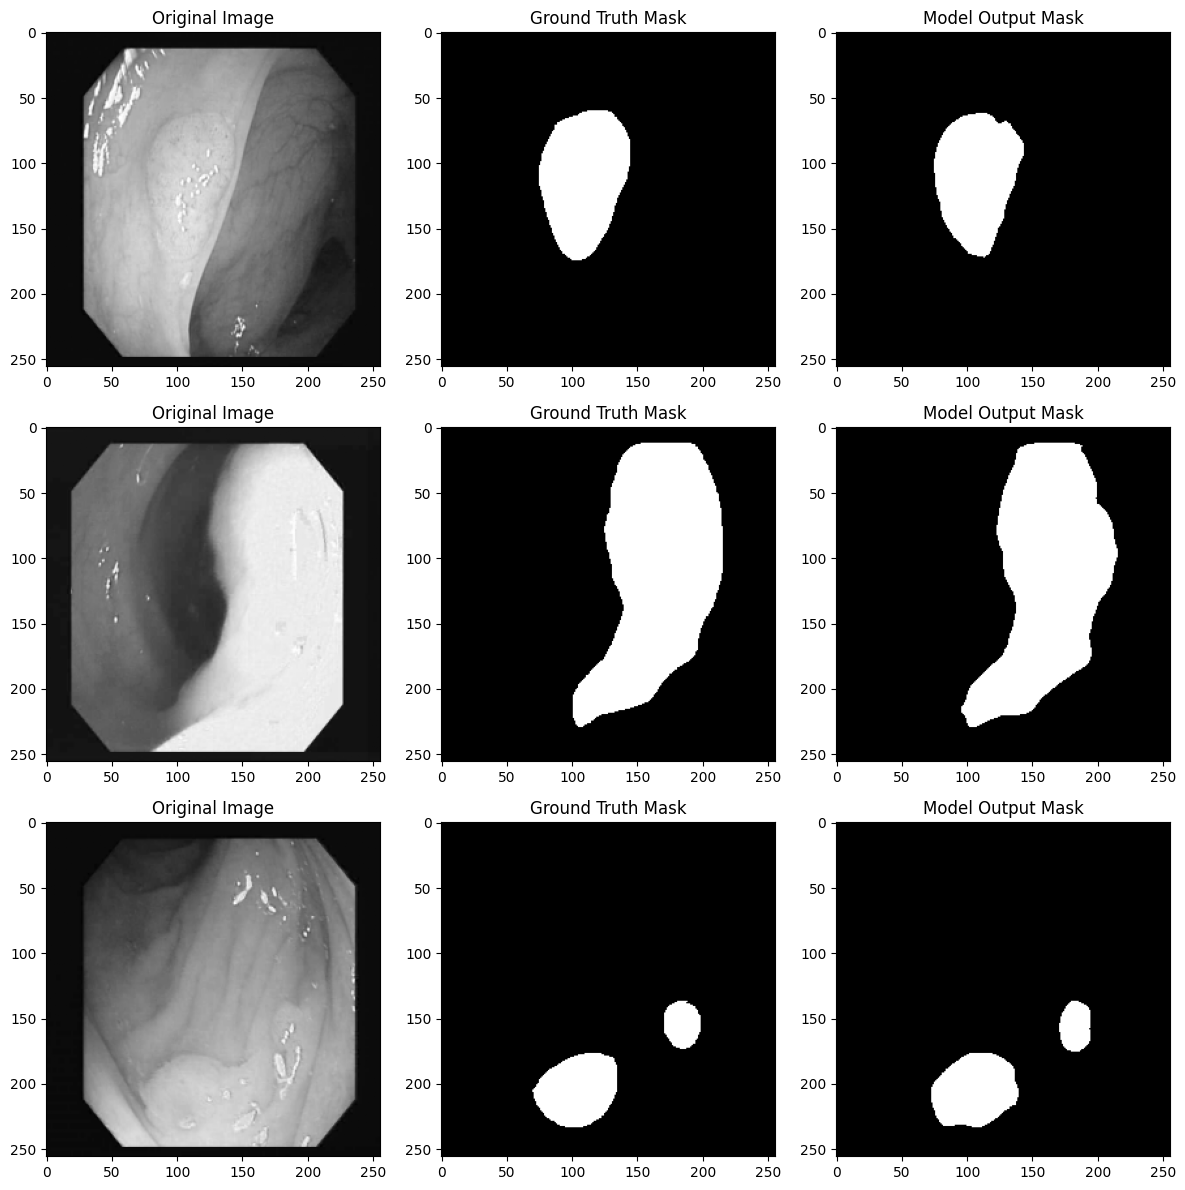

In [8]:
trainer.visualize_output_samples()

In [9]:
trainer.validate_and_save()

100%|██████████| 8/8 [00:00<00:00, 10.25it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.2488
Average Dice Score                 : 0.7925
Average Hausdorff Distance         : inf
Average IoU                        : 0.7243
Precision                          : 0.9535
Recall                             : 0.8115
F1 Score                           : 0.8768
IoU (batch avg)                    : 0.7604
Dice (batch avg)                   : 0.8547
Total Parameters                   : 26,082,361
Trainable Parameters               : 26,082,361
Average Inference Time (seconds)   : 0.009226
FPS (Frames Per Second)            : 108.39
FLOPs                              : 8,979,154,432.0
GFLOPs                             : 8.9792

Results saved to: model_comparisons/evaluation_results/DeepLabV3Plus_model_CVC-ClinicDB_evaluation_results_20250908_080225.csv
Validation results saved to model_comparisons/evaluation_results/DeepLabV3Plus_model_CVC-ClinicDB_evaluation_results


{'test_loss': 0.24877799861133099,
 'avg_dice_score': 0.7925279109318847,
 'avg_hd_score': inf,
 'avg_iou': 0.7242998305438463,
 'precision': 0.9534925154380646,
 'recall': 0.8114524060866655,
 'f1': 0.8767568737152837,
 'iou_batch_avg': 0.7604431696236134,
 'dice_batch_avg': 0.8546827584505081,
 'total_params': 26082361,
 'trainable_params': 26082361,
 'avg_inference_time': 0.009226202964782715,
 'fps': 108.38695006137347,
 'flops': 8979154432.0,
 'gflops': 8.979154432}

# **Kvasir-SEG dataset**

Total number of samples: 1000
Number of training samples: 900
Number of testing samples: 100


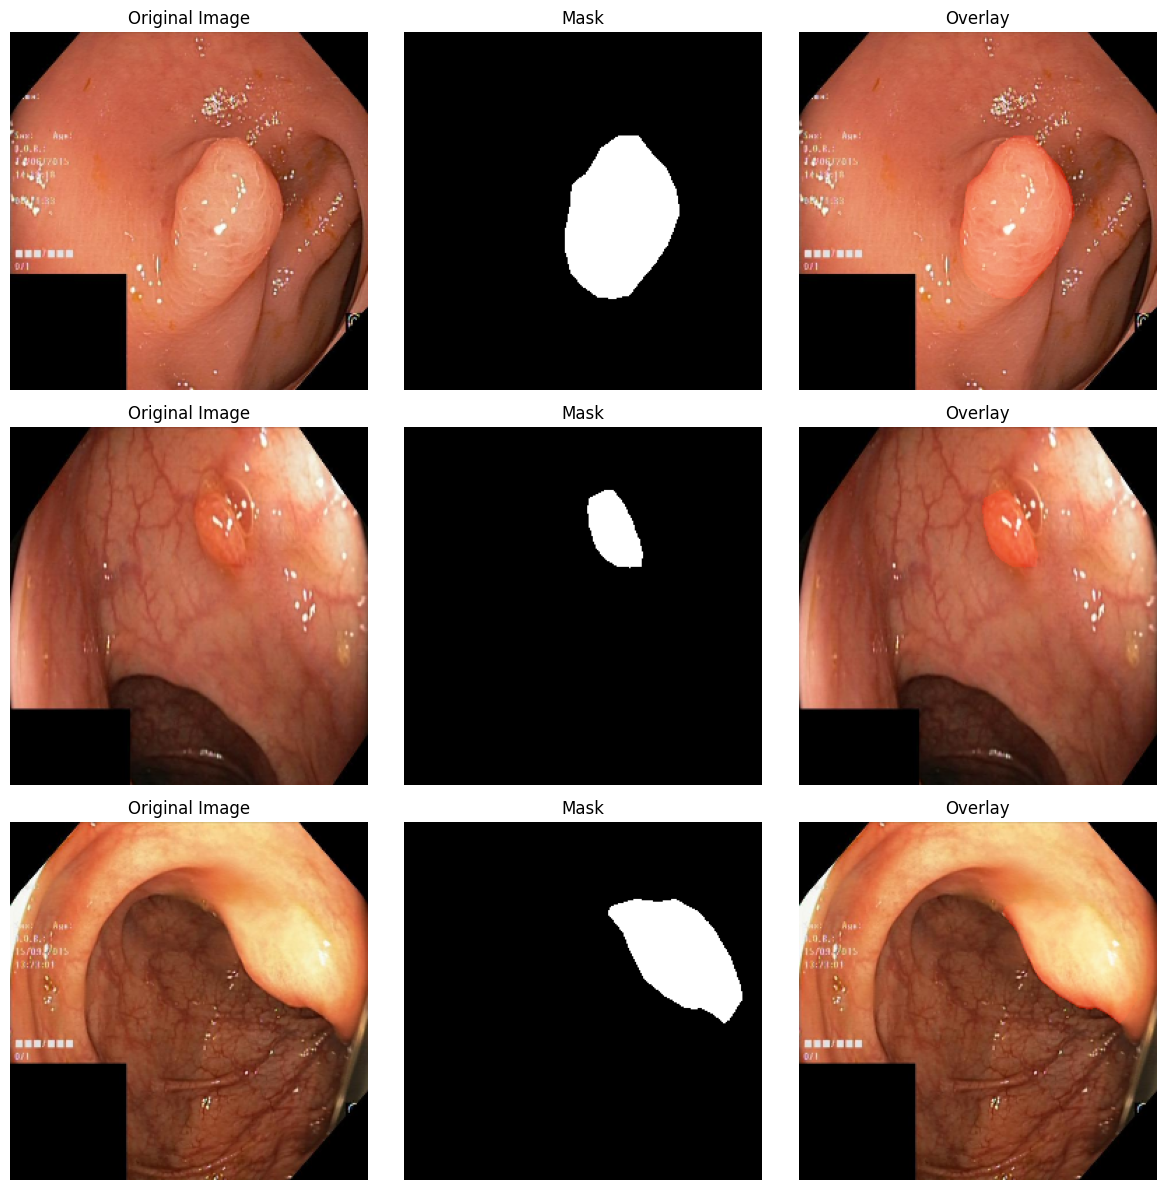

In [10]:
# Dataset Paths
dataset_path = "data/Kvasir-SEG"
image_dir = "images"
mask_dir = "masks"

# Image Preprocessing Parameters
IMG_SIZE = (256, 256)  # Changed to (256, 256) as per the context

dataset = MedicalImageSegmentationData(
    dataset_path=dataset_path,
    image_dir=image_dir,
    mask_dir=mask_dir,
    img_size=IMG_SIZE,
    batch_size=8,
    test_size=0.1,
    random_state=42,
    binarize_mask=True,
)

train_loader, test_loader = dataset.dataloaders()

print(f"Total number of samples: {len(dataset)}")
print(f"Number of training samples: {len(train_loader.dataset)}")
print(f"Number of testing samples: {len(test_loader.dataset)}")

dataset.visualize_samples()

# UNet Kvasir training config

In [11]:
import torch
from segmentation_models import *

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("CUDA device found.")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("MPS device found.")
else:
    device = torch.device("cpu")
    print("Using CPU.")

CUDA device found.


In [12]:
cfg = TrainConfig(
    # --- General ---
    model_name = "DeepLabV3Plus",
    dataset_name = "Kvasir-SEG",
    criterion = "BCEDiceLoss",
    optimizer = "AdamW",
    epochs = 100,
    lr = 1e-3,
    weight_decay = 1e-4,

    # --- Scheduler ---
    scheduler = "ReduceLROnPlateau",
    scheduler_factor = 0.5,          # for ReduceLROnPlateau
    scheduler_patience = 5,            # for ReduceLROnPlateau
    mode = "min",

    # --- Training control ---
    early_stopping_patience = 10,

    # --- Paths / logging ---
    base_dir="model_comparisons",
    models_dir = "trained_models",
    history_dir = "models_history",
    loss_dir = "loss_plots",
    visualize_dir = "visualizations",
    logs_dir = "logs",
    use_wandb = True,
    wandb_project = "segmentation_models",
    wandb_run_name = None,
    wandb_watch_log_freq = 100,

    # --- Metrics ---
    threshold = 0.5,
    log_train_metrics = True
)

In [13]:
if cfg.use_wandb:
    from dotenv import load_dotenv
    load_dotenv()
    import wandb
    wandb.login(key=os.getenv("WANDB_API_KEY"))

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: Appending key for api.wandb.ai to your netrc file: /home/humblebee/.netrc


In [14]:
model = deeplabv3plus_resnet34(num_classes=1, pretrained=False, output_stride=16)
trainer = SegmentationTrainer(model, device, train_loader, test_loader, test_loader, cfg=cfg)
result = trainer.train()
result


/media/data/Mironshoh/segmentation-paper/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/media/data/Mironshoh/segmentation-paper/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
2025-09-08 08:06:24 | INFO | DeepLabV3Plus_model_Kvasir_SEG_20250908_080624 | Logging to model_comparisons/logs/DeepLabV3Plus_model_Kvasir_SEG_20250908_080624.log


2025-09-08 08:06:24 | INFO | DeepLabV3Plus_model_Kvasir_SEG_20250908_080624 | W&B URL: https://wandb.ai/iv-drip-counter/segmentation_models/runs/rrtvvypk
100%|██████████| 13/13 [00:01<00:00,  7.06it/s]
2025-09-08 08:06:33 | INFO | DeepLabV3Plus_model_Kvasir_SEG_20250908_080624 | Epoch 001/100 | Train: 1.386986 | Val: 0.891354 | LR: 0.001000 | 8.51s | Val Dice: 0.4427 IoU: 0.3198 F1: 0.4894
2025-09-08 08:06:33 | INFO | DeepLabV3Plus_model_Kvasir_SEG_20250908_080624 | Saved best: model_comparisons/models/best_DeepLabV3Plus_model_Kvasir_SEG_20250908_080624.pth (val=0.891354)
100%|██████████| 13/13 [00:01<00:00,  8.59it/s]
2025-09-08 08:06:42 | INFO | DeepLabV3Plus_model_Kvasir_SEG_20250908_080624 | Epoch 002/100 | Train: 0.940207 | Val: 0.858650 | LR: 0.001000 | 8.28s | Val Dice: 0.4896 IoU: 0.3542 F1: 0.5298
2025-09-08 08:06:42 | INFO | DeepLabV3Plus_model_Kvasir_SEG_20250908_080624 | Saved best: model_comparisons/models/best_DeepLabV3Plus_model_Kvasir_SEG_20250908_080624.pth (val=0.8586

avg_flops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_fps,█▇▆█▇█▄▇▆█▇▇▇███▇▇▅▆█▁████▇▇▇▇███▆
avg_gflops,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
avg_inference_time,▁▂▃▁▂▁▅▂▂▁▂▂▂▁▁▁▂▂▄▂▁█▁▁▁▁▂▂▂▁▁▁▁▃
epoch_seconds,▃▃▁▅▆▄▂▂▃▁▇█▅▄▃▄▇▅▇█▃▃▂▂▂▁▃▅▆▃▂▁▁▃
lr,█████████████████████▃▃▃▃▃▃▃▃▁▁▁▁▁
num_trainable,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/dice,▁▂▂▃▃▃▃▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇█████████
train/f1,▁▂▂▃▃▃▃▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇█████████
train/iou,▁▂▂▂▂▃▃▃▃▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇██████
+11,...


{'best_val_loss': 0.362930749471371,
 'epochs_ran': 34,
 'best_model_path': 'model_comparisons/models/best_DeepLabV3Plus_model_Kvasir_SEG_20250908_080624.pth',
 'loss_csv_path': 'model_comparisons/history/loss_history_DeepLabV3Plus_Kvasir_SEG_20250908_080624.csv',
 'wandb_url': 'https://wandb.ai/iv-drip-counter/segmentation_models/runs/rrtvvypk',
 'log_path': 'model_comparisons/logs/DeepLabV3Plus_model_Kvasir_SEG_20250908_080624.log'}

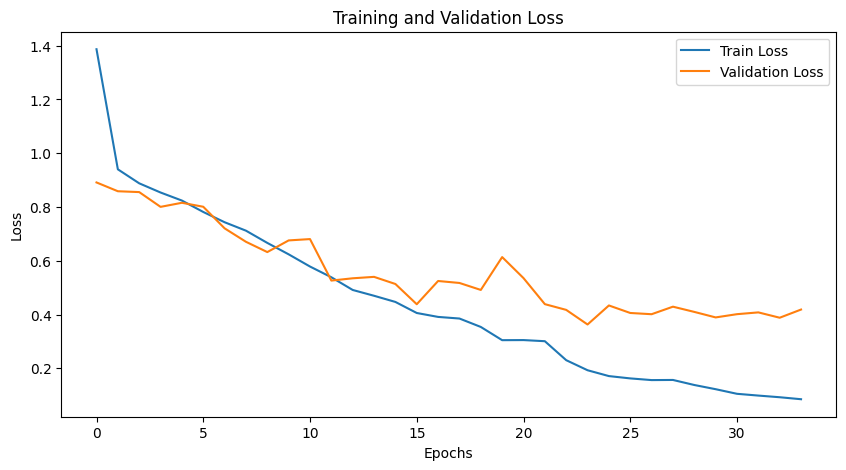

In [15]:
trainer.plot_losses()

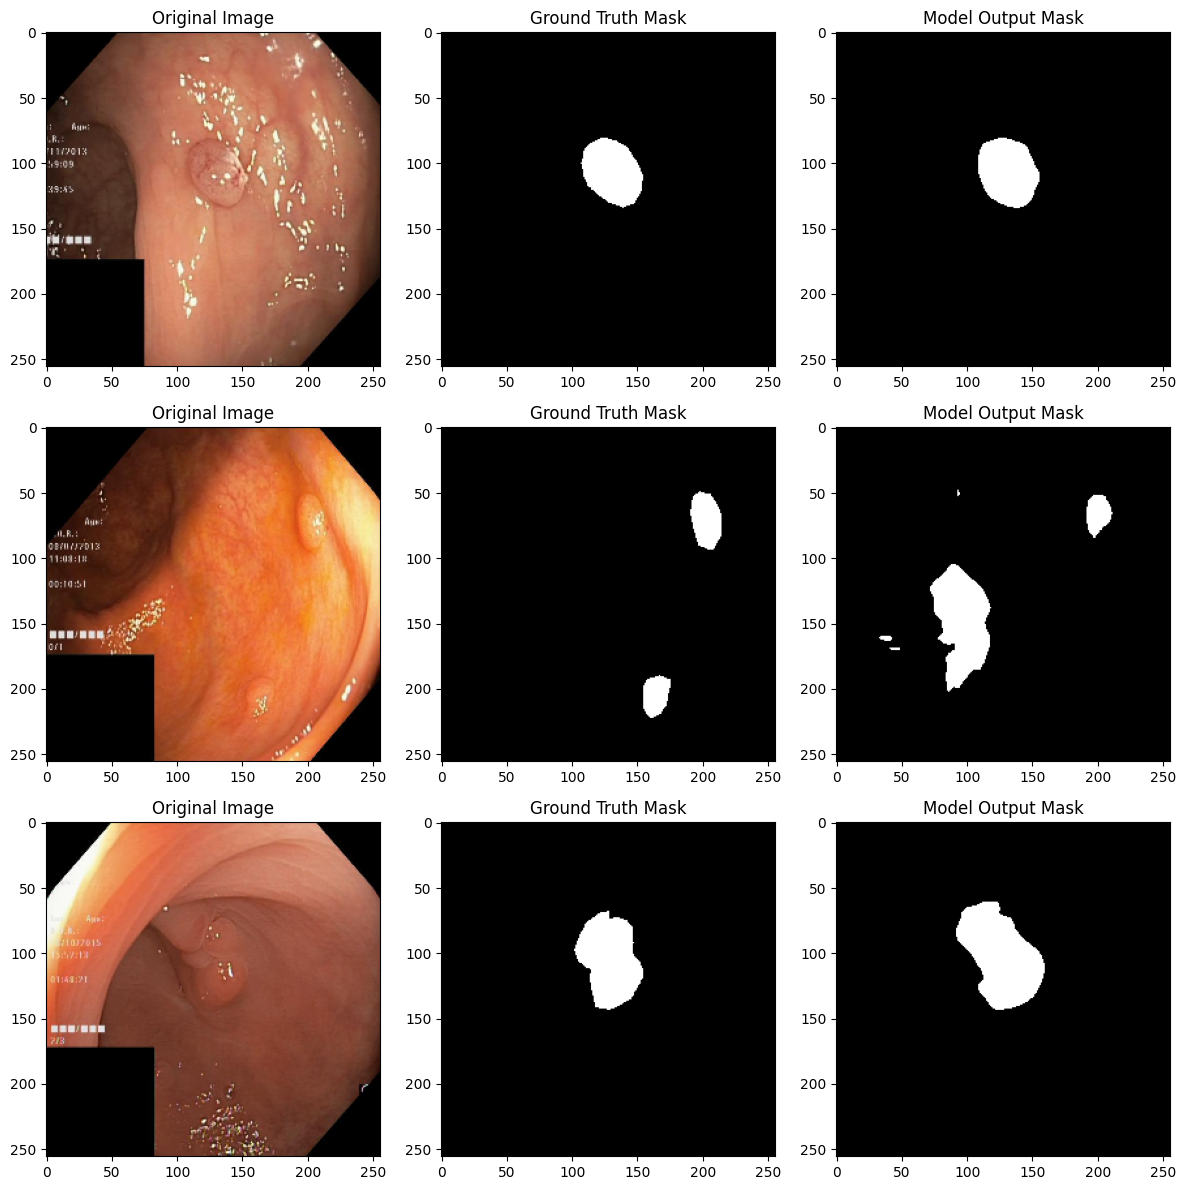

In [16]:
trainer.visualize_output_samples()

In [17]:
trainer.validate_and_save()

100%|██████████| 13/13 [00:01<00:00,  6.71it/s]



MODEL EVALUATION RESULTS
Test Loss                          : 0.4185
Average Dice Score                 : 0.8178
Average Hausdorff Distance         : 41.4493
Average IoU                        : 0.7401
Precision                          : 0.8676
Recall                             : 0.7929
F1 Score                           : 0.8286
IoU (batch avg)                    : 0.7159
Dice (batch avg)                   : 0.8303
Total Parameters                   : 26,082,361
Trainable Parameters               : 26,082,361
Average Inference Time (seconds)   : 0.009963
FPS (Frames Per Second)            : 100.37
FLOPs                              : 8,979,154,432.0
GFLOPs                             : 8.9792

Results saved to: model_comparisons/evaluation_results/DeepLabV3Plus_model_Kvasir-SEG_evaluation_results_20250908_080624.csv
Validation results saved to model_comparisons/evaluation_results/DeepLabV3Plus_model_Kvasir-SEG_evaluation_results


{'test_loss': 0.41851322238261884,
 'avg_dice_score': 0.8178320151940699,
 'avg_hd_score': 41.449334228038786,
 'avg_iou': 0.7400817357004399,
 'precision': 0.8675645441172585,
 'recall': 0.7928939659692055,
 'f1': 0.8285502925135768,
 'iou_batch_avg': 0.7159424676344945,
 'dice_batch_avg': 0.8303418021935683,
 'total_params': 26082361,
 'trainable_params': 26082361,
 'avg_inference_time': 0.00996316909790039,
 'fps': 100.36967055098334,
 'flops': 8979154432.0,
 'gflops': 8.979154432}